In [ ]:
import sys
import json
from pathlib import Path

_root = next(p for p in Path.cwd().resolve().parents if (p / '.git').exists() or (p / 'setup.py').exists())
for _p in (str(_root), str(_root / 'src')):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from metab_processing.LinearRegression import signature_helpers as sh, signature_batch as sb
from metab_processing.LinearRegression.signature_configs import CONFIGS

cfg = CONFIGS['breast']

# Which ratio plots `view()` renders (keys of sh.plot_res).
PLOTS = ('ratio', 'variance_ratio', 'meansq_variance_ratio')
# ---- Which cached fit to READ (must match a computed params subdir) ----
# Default = this config's fit (l1 @ penalty 0.005). To read a different fit, override, e.g.:
#   READ = dict(method='ridge', penalty=800)
READ = dict(method=cfg.method, penalty=cfg.penalty, l1_ratio=cfg.l1_ratio)

In [3]:
membership = json.load(open(Path(cfg.cache_dir) / '_membership.json'))
print(f'{cfg.name}: loaded membership for {len(membership)} gene set(s)')

breast: loaded membership for 34 gene set(s)


## breast: target signatures -- membership, missing, present, factor-removed, remaining

In [4]:
print(f'===== {cfg.name} target signatures: membership + factor-removal =====')
for name in list(cfg.target_signatures) + list(cfg.neg_controls) + list(cfg.manual_sets):
    m = membership.get(name, {})
    print(f'\n{name}')
    print(f"  present ({len(m.get('present', []))}): {m.get('present', [])}")
    print(f"  missing ({len(m.get('missing', []))}): {m.get('missing', [])}")
    print(f"  total: {m.get('total', 0)}")
    print(f"  factor_removed ({len(m.get('factor_removed', []))}): {m.get('factor_removed', [])}")
    print(f"  remaining ({len(m.get('remaining', []))}): {m.get('remaining', [])}")

===== breast target signatures: membership + factor-removal =====

HALLMARK_IL2_STAT5_SIGNALING
  present (199): ['ABCB1', 'ADAM19', 'AGER', 'AHCY', 'AHNAK', 'AHR', 'ALCAM', 'AMACR', 'ANXA4', 'APLP1', 'ARL4A', 'BATF', 'BATF3', 'BCL2', 'BCL2L1', 'BHLHE40', 'BMP2', 'BMPR2', 'CA2', 'CAPG', 'CAPN3', 'CASP3', 'CCND2', 'CCND3', 'CCNE1', 'CCR4', 'CD44', 'CD48', 'CD79B', 'CD81', 'CD83', 'CD86', 'CDC42SE2', 'CDC6', 'CDCP1', 'CDKN1C', 'CISH', 'CKAP4', 'COCH', 'COL6A1', 'CSF1', 'CSF2', 'CST7', 'CTLA4', 'CTSZ', 'CXCL10', 'CYFIP1', 'DCPS', 'DENND5A', 'DHRS3', 'DRC1', 'ECM1', 'EEF1AKMT1', 'EMP1', 'ENO3', 'ENPP1', 'EOMES', 'ETFBKMT', 'ETV4', 'F2RL2', 'FAH', 'FGL2', 'FLT3LG', 'FURIN', 'GABARAPL1', 'GADD45B', 'GALM', 'GATA1', 'GBP4', 'GLIPR2', 'GPR65', 'GPR83', 'GPX4', 'GSTO1', 'GUCY1B1', 'HIPK2', 'HK2', 'HOPX', 'HUWE1', 'HYCC2', 'ICOS', 'IFITM3', 'IFNGR1', 'IGF1R', 'IGF2R', 'IKZF2', 'IKZF4', 'IL10', 'IL10RA', 'IL13', 'IL18R1', 'IL1R2', 'IL1RL1', 'IL2RA', 'IL2RB', 'IL3RA', 'IL4R', 'IRF4', 'IRF6', 'IRF8

## View helper -- `view(sig)` renders every cached run-spec for one signature

In [5]:
TARGETS = sb.all_targets(cfg)   # targets + neg controls + manual sets (+ colon single gene)
specs = sb.runspecs(cfg)


def view(sig):
    for spec in specs:
        res = sb.load_res(cfg, sig, spec['label'], **READ)
        if res is None:
            print('not yet computed:', sig, spec['label'])
            continue
        sh.plot_res(res, highlight_genes=membership.get(sig, {}).get('present', []),
                    title=f"{sig} | {spec['label']}", plots=PLOTS)

## Metabolic targets (predicted like the T-cell signatures)

In [6]:
view('HALLMARK_HYPOXIA')

not yet computed: HALLMARK_HYPOXIA T Lymphocytes_only


In [7]:
view('HALLMARK_GLYCOLYSIS')

not yet computed: HALLMARK_GLYCOLYSIS T Lymphocytes_only


In [8]:
view('HALLMARK_OXIDATIVE_PHOSPHORYLATION')

not yet computed: HALLMARK_OXIDATIVE_PHOSPHORYLATION T Lymphocytes_only


In [9]:
view('HALLMARK_FATTY_ACID_METABOLISM')

not yet computed: HALLMARK_FATTY_ACID_METABOLISM T Lymphocytes_only


In [10]:
view('HALLMARK_MTORC1_SIGNALING')

not yet computed: HALLMARK_MTORC1_SIGNALING T Lymphocytes_only


## Subsample stats from cached raw betas -- call `stats('SIGNATURE_NAME')`

In [11]:
# 95% CI / selection-frequency / stability, computed directly from the cached raw subsample
# betas. (CI at n_sub resamples is coarse; under L1 betas pile at 0 so selection_freq + a
# CI excluding 0 are the honest signals, p_stability is a conservative heuristic.)
from IPython.display import display

def stats(sig):
    for spec in specs:
        betas = sb.load_betas(cfg, sig, spec['label'], **READ)
        if betas is None:
            print('not yet computed:', sig, spec['label']); continue
        print(f"\n=== {sig} | {spec['label']} ===")
        display(sh.subsample_stats(betas).sort_values('selection_freq', ascending=False).head(25))

## T-cell TARGET signatures

### HALLMARK_IL2_STAT5_SIGNALING

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


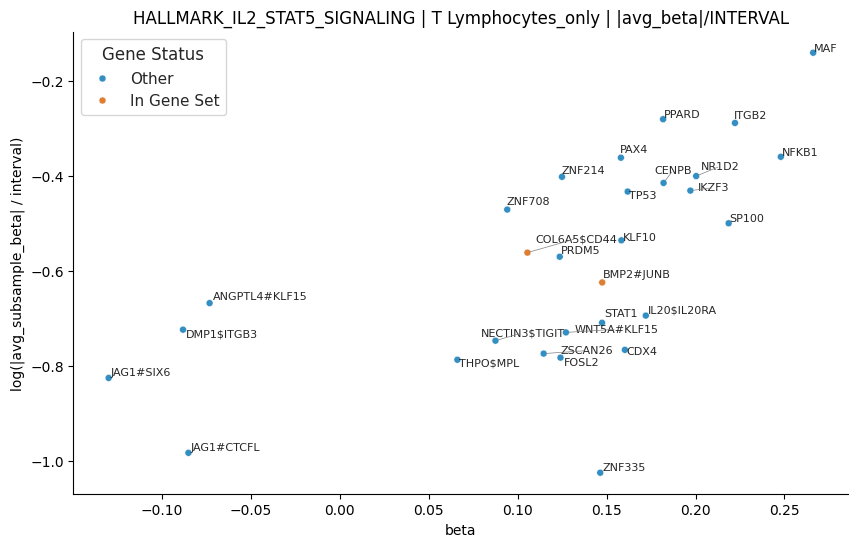

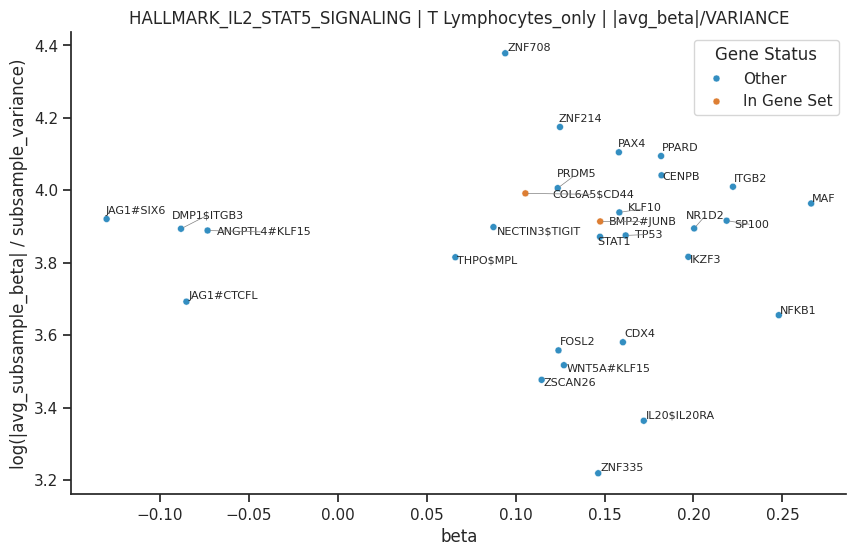

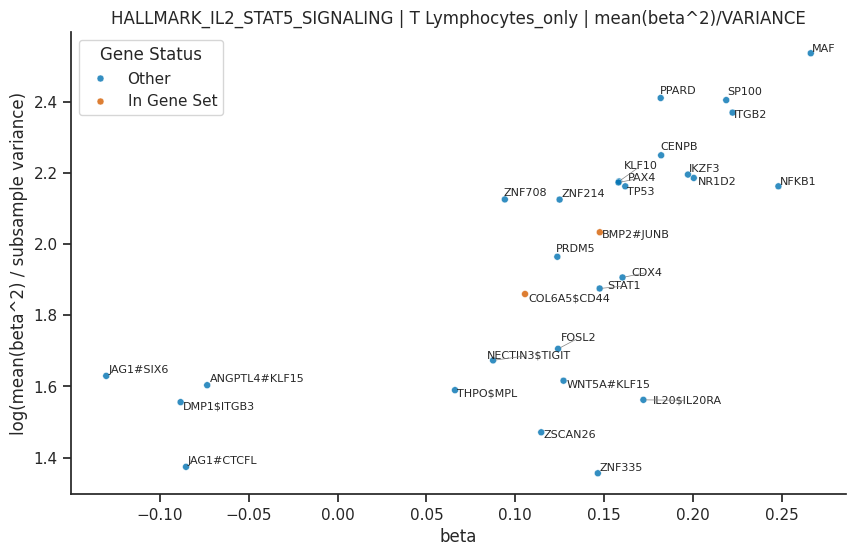

In [12]:
view('HALLMARK_IL2_STAT5_SIGNALING')

### KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY

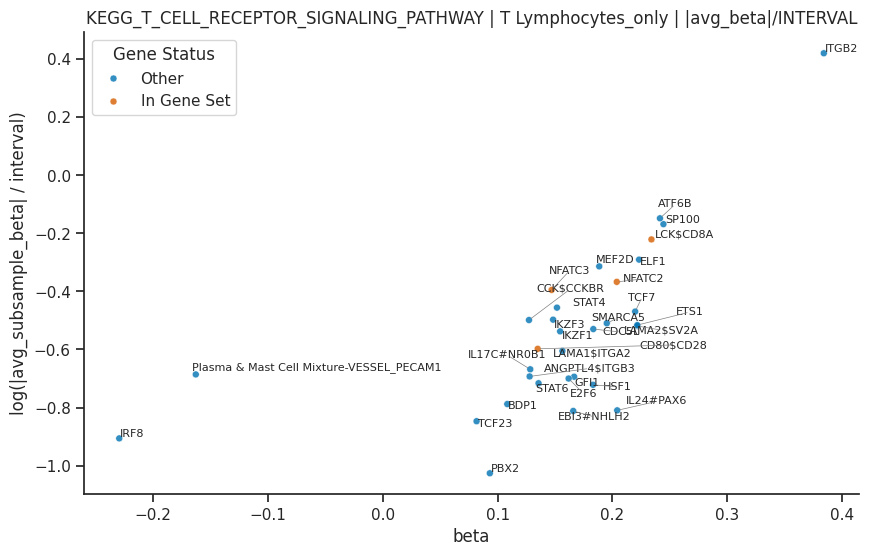

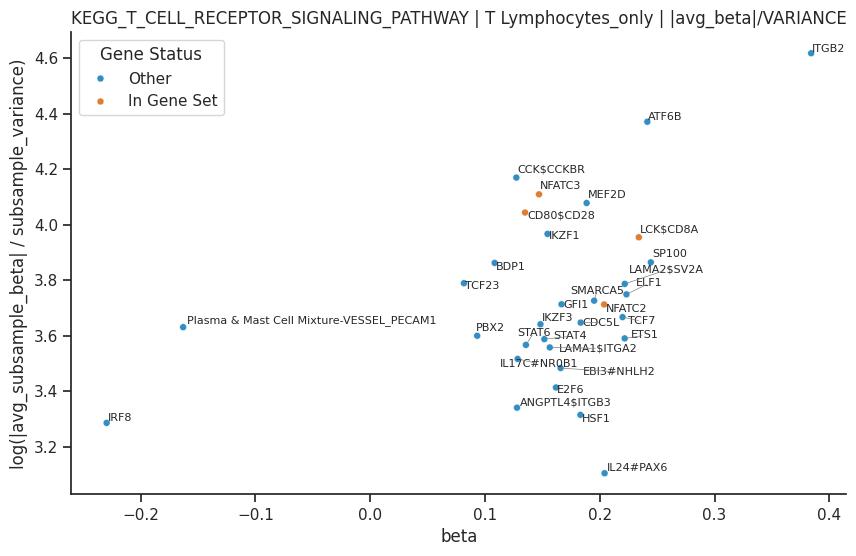

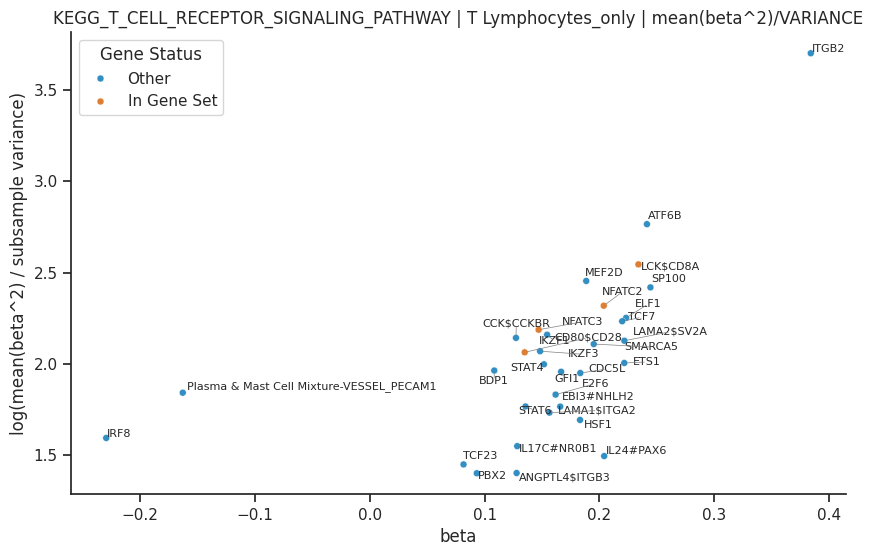

In [13]:
view('KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY')

### GOBP_T_CELL_MEDIATED_CYTOTOXICITY

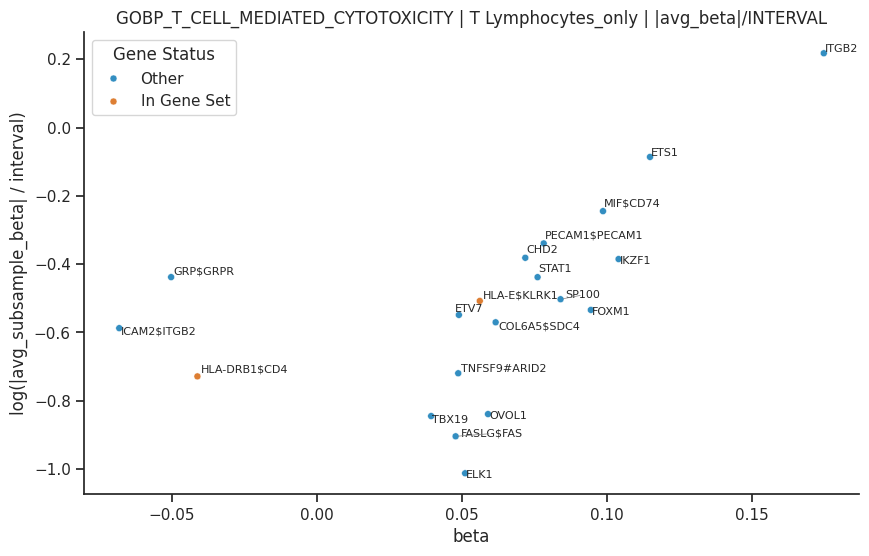

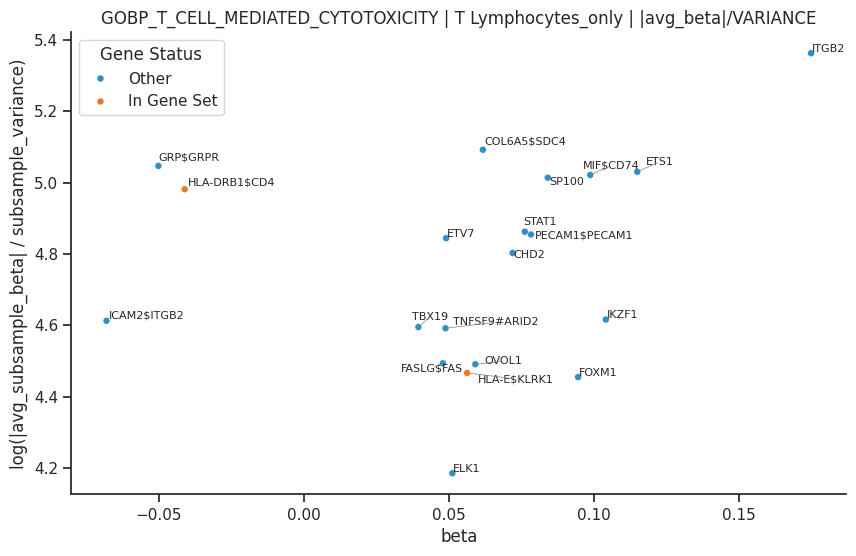

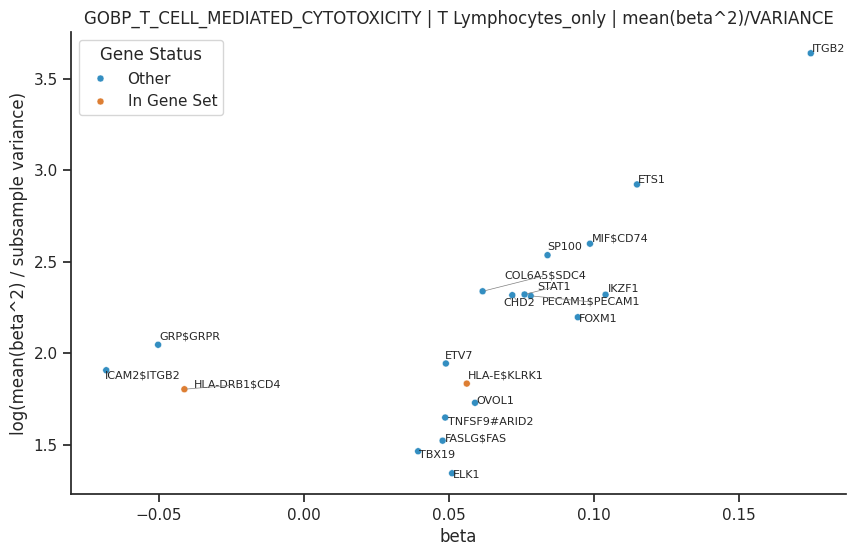

In [14]:
view('GOBP_T_CELL_MEDIATED_CYTOTOXICITY')

### KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY

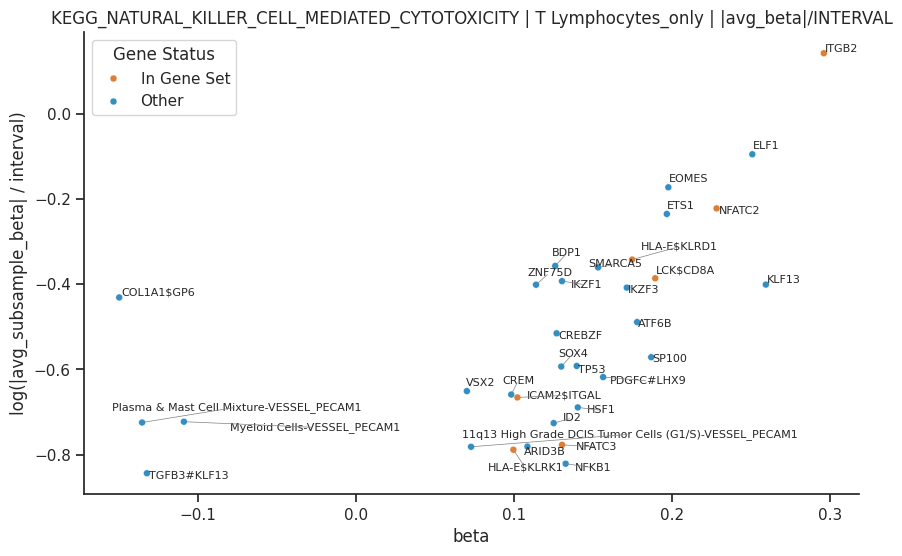

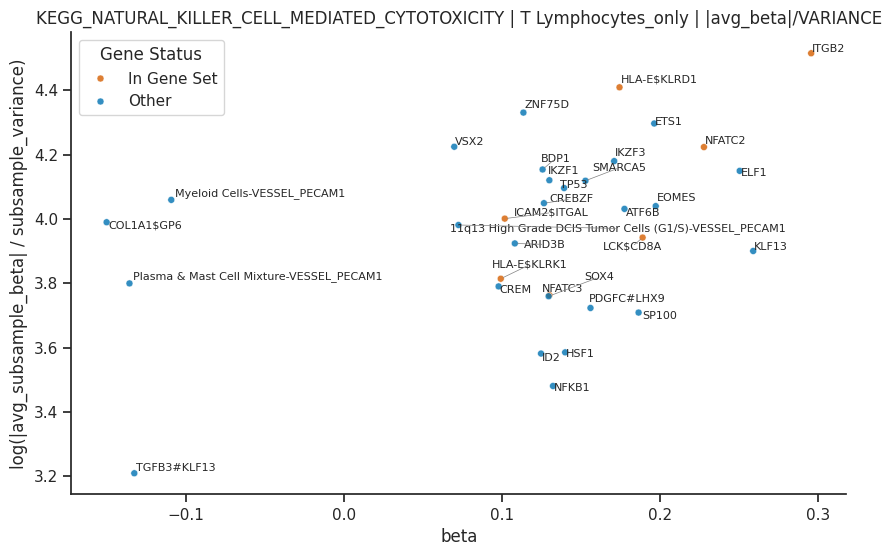

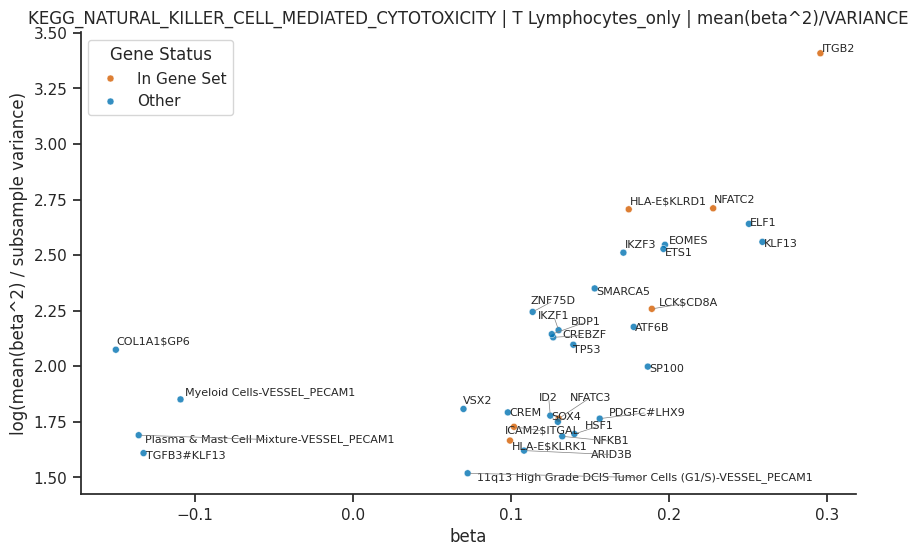

In [15]:
view('KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY')

### HALLMARK_TNFA_SIGNALING_VIA_NFKB

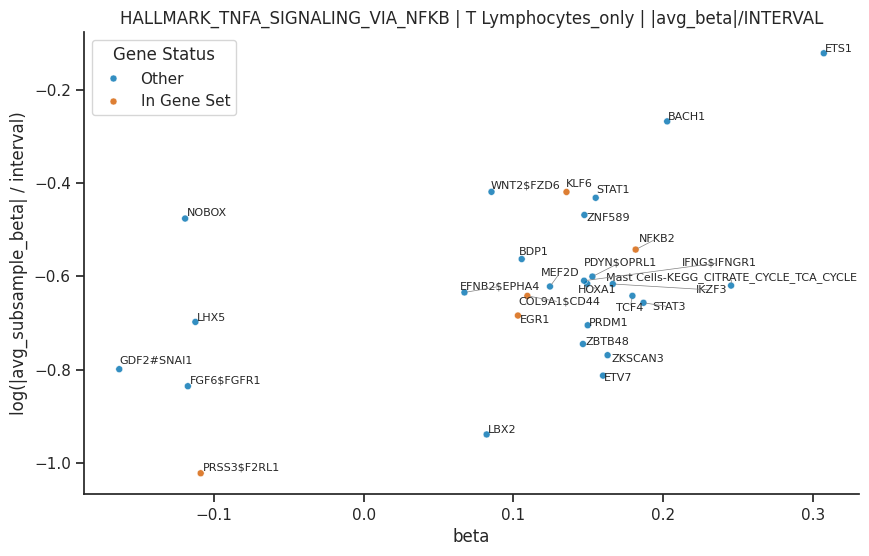

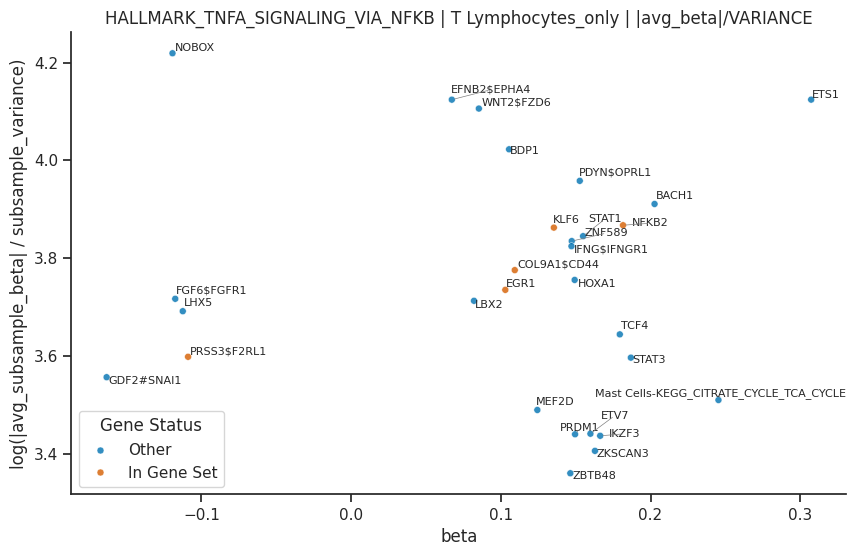

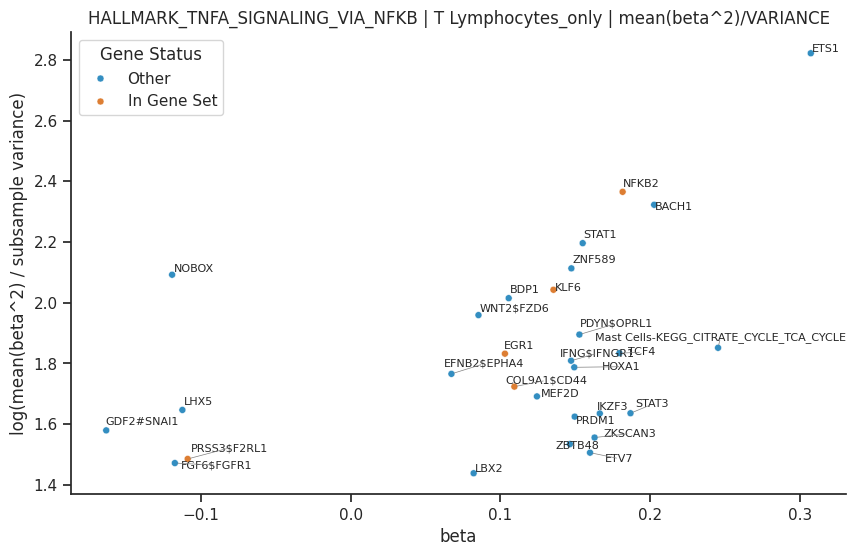

In [16]:
view('HALLMARK_TNFA_SIGNALING_VIA_NFKB')

### HALLMARK_INTERFERON_GAMMA_RESPONSE

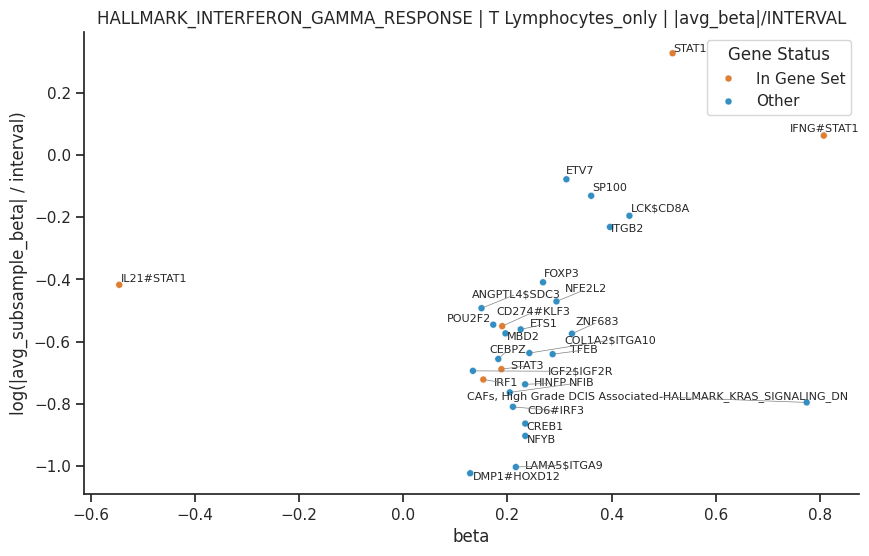

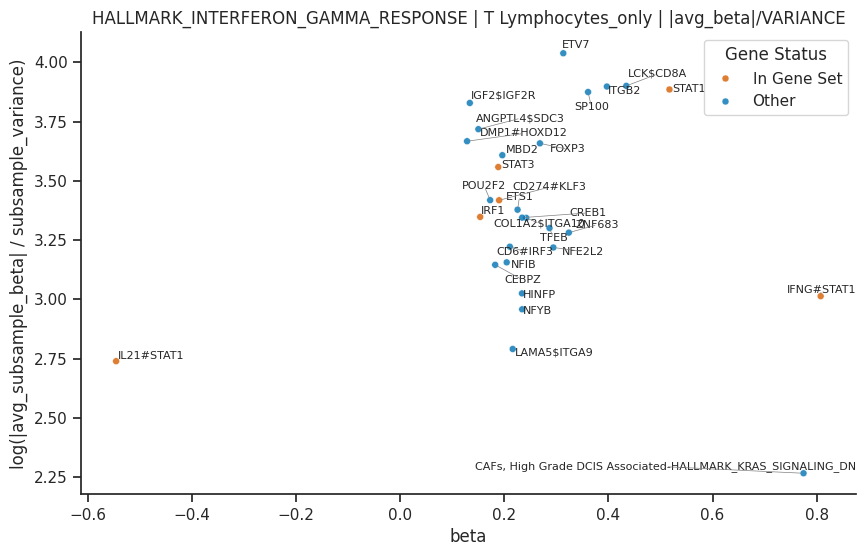

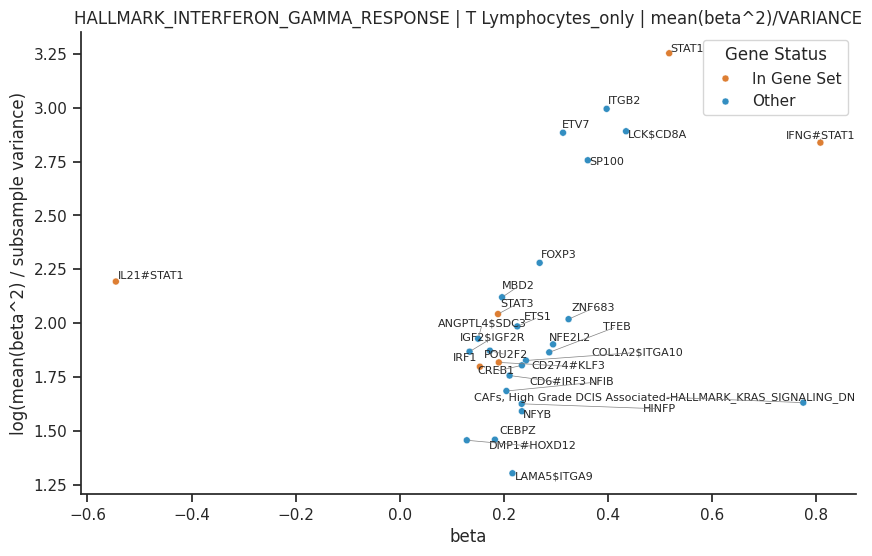

In [17]:
view('HALLMARK_INTERFERON_GAMMA_RESPONSE')

### HALLMARK_INTERFERON_ALPHA_RESPONSE

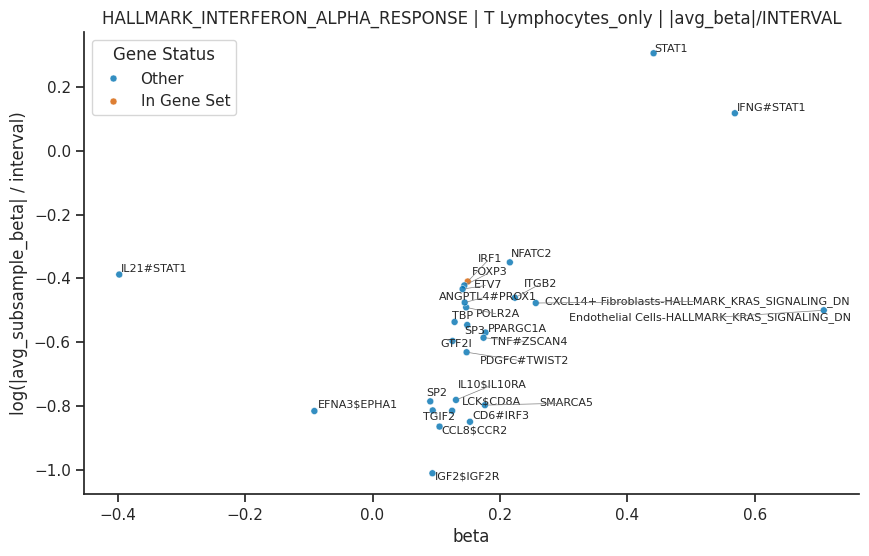

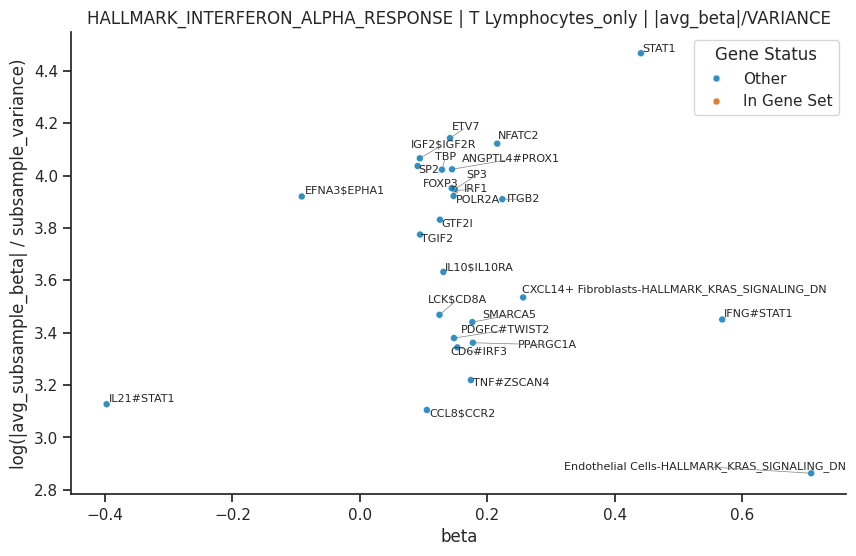

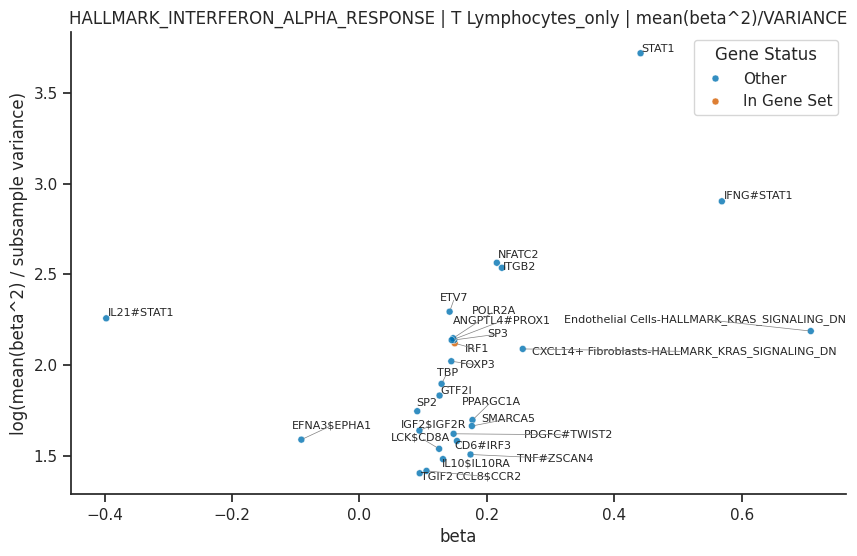

In [18]:
view('HALLMARK_INTERFERON_ALPHA_RESPONSE')

### GOBP_CELL_KILLING

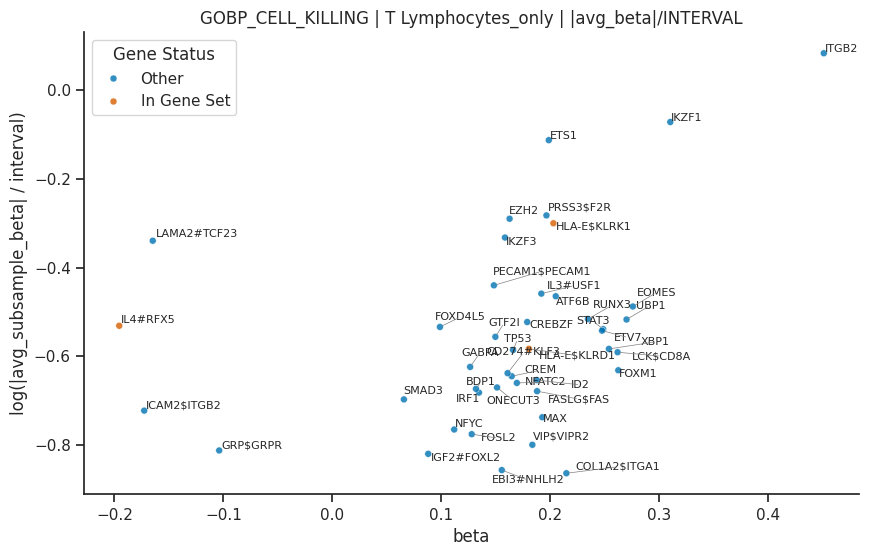

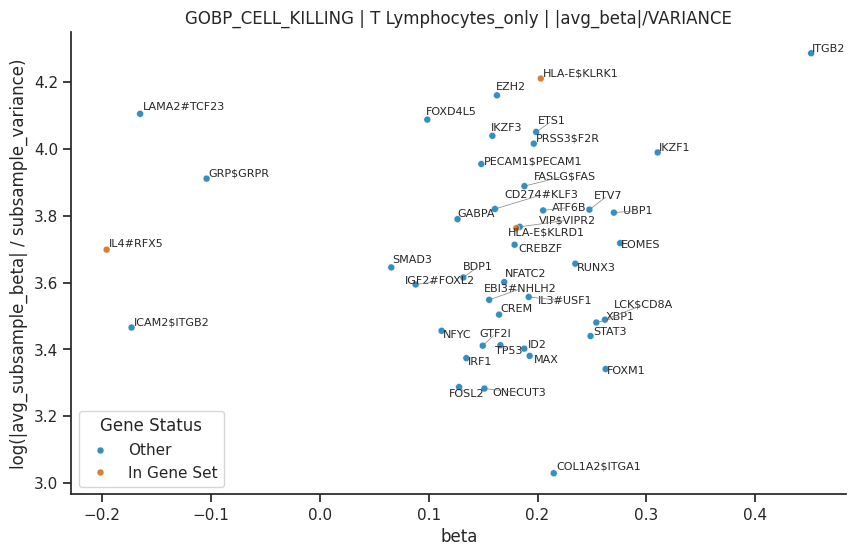

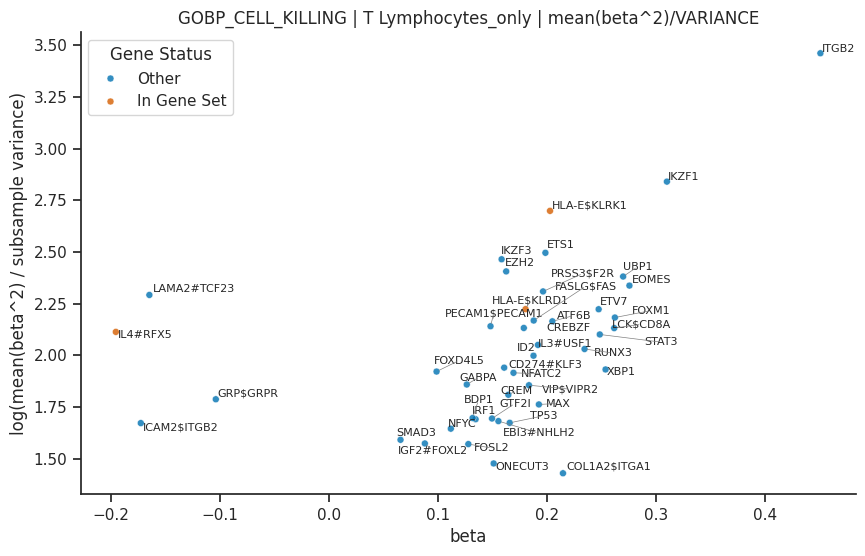

In [19]:
view('GOBP_CELL_KILLING')

### GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY

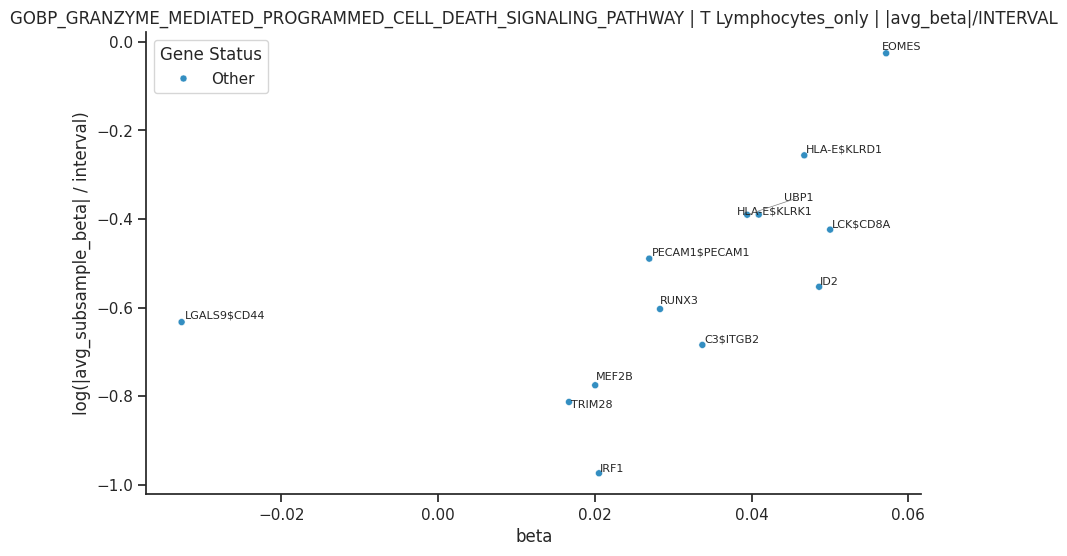

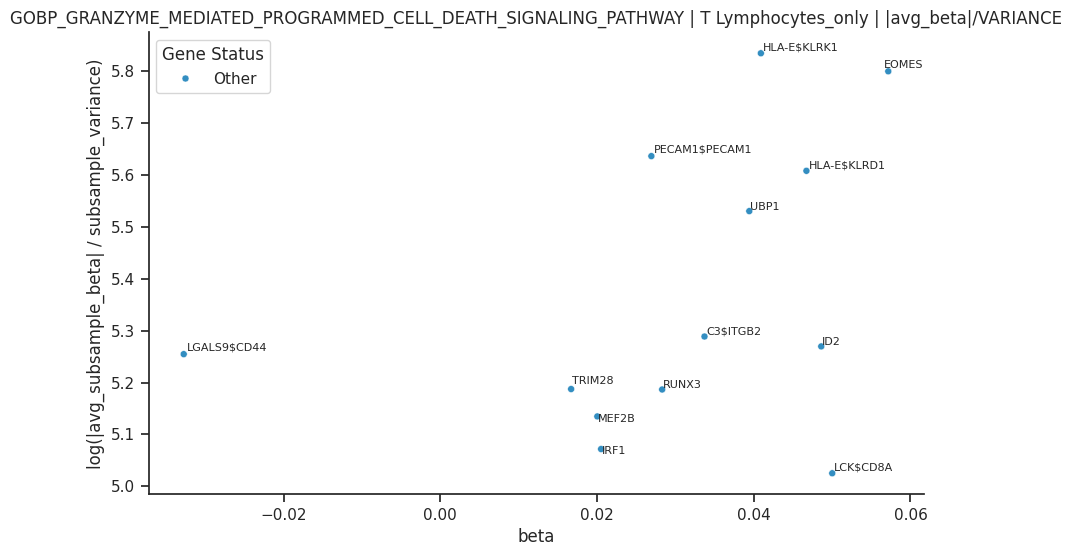

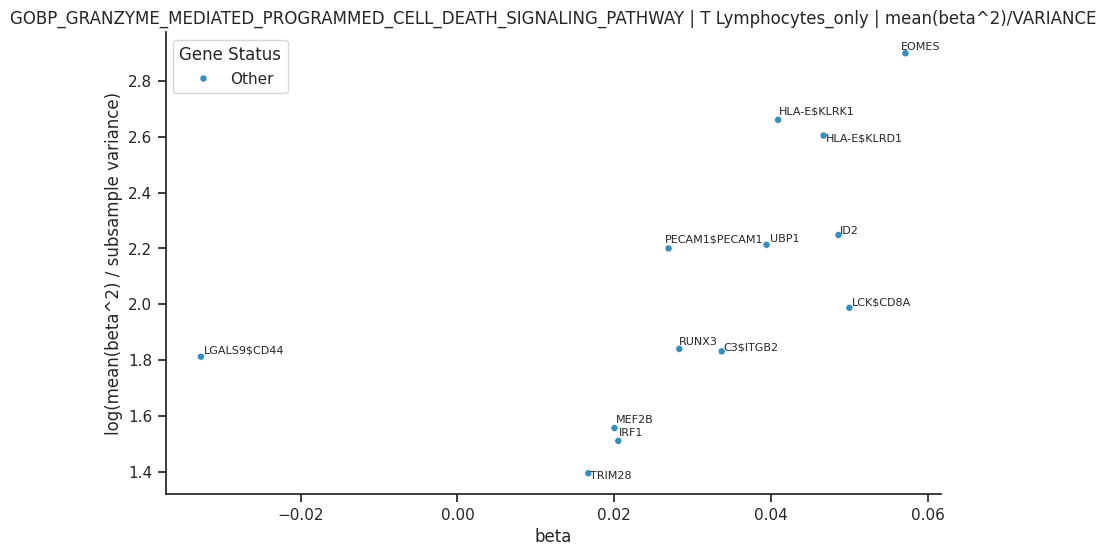

In [20]:
view('GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY')

### GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY

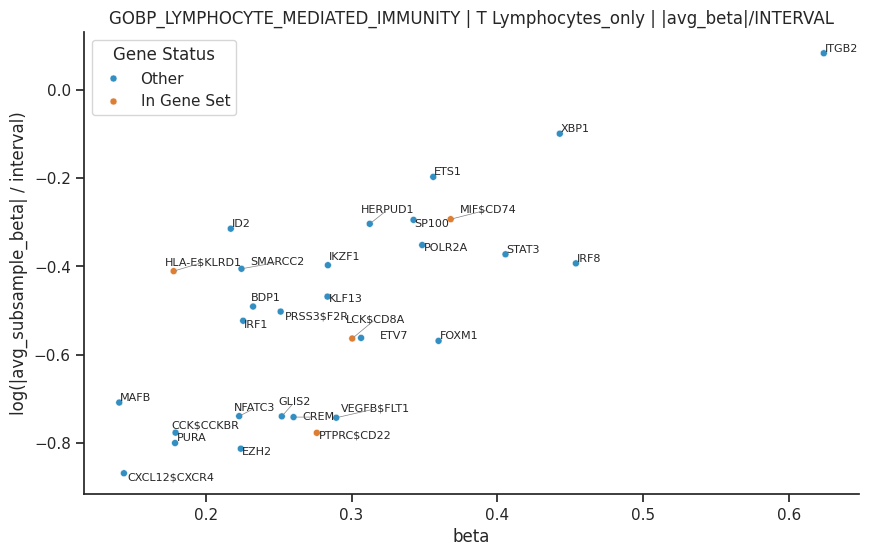

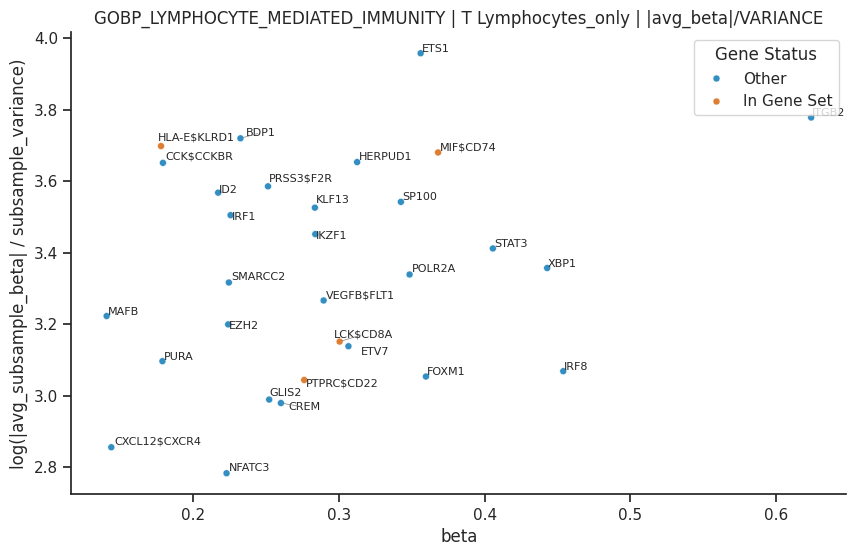

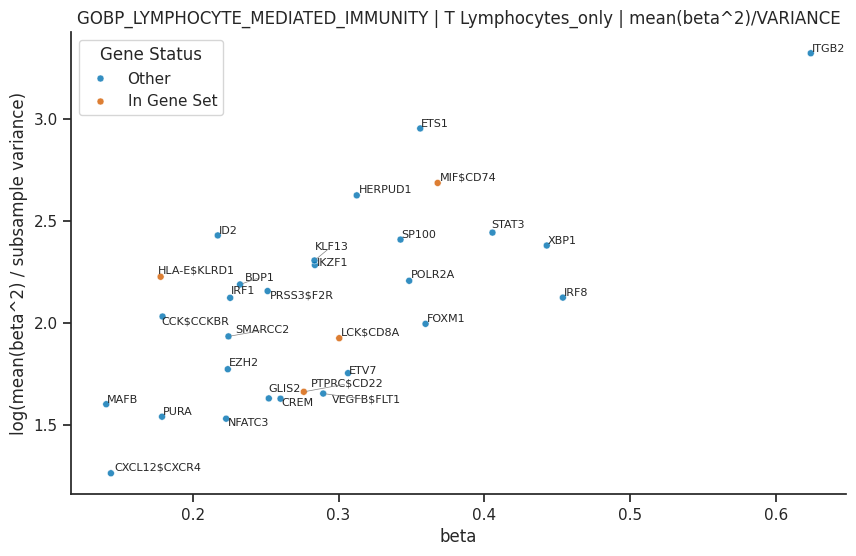

In [21]:
view('GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY')

## Negative controls

### HALLMARK_PANCREAS_BETA_CELLS

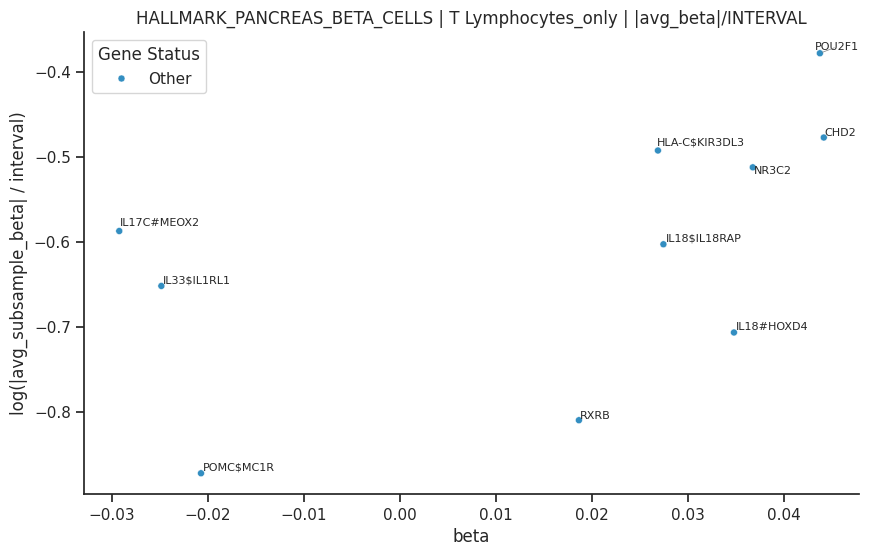

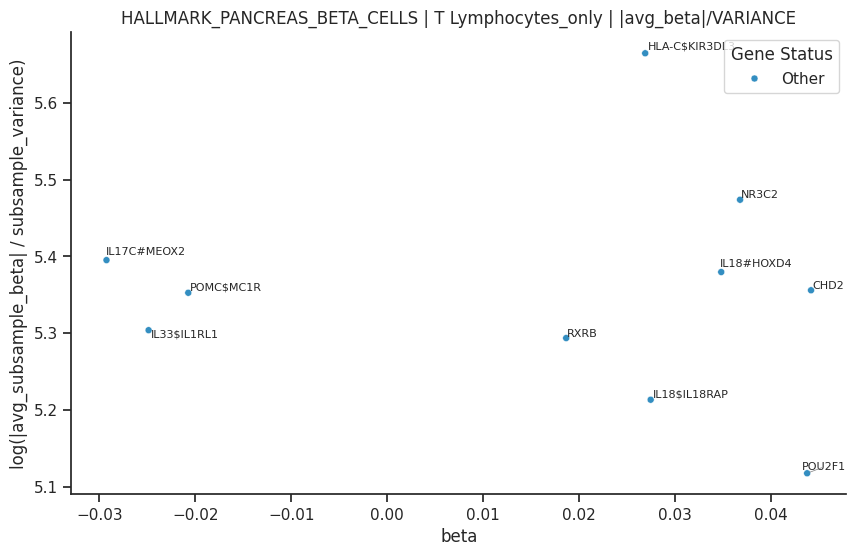

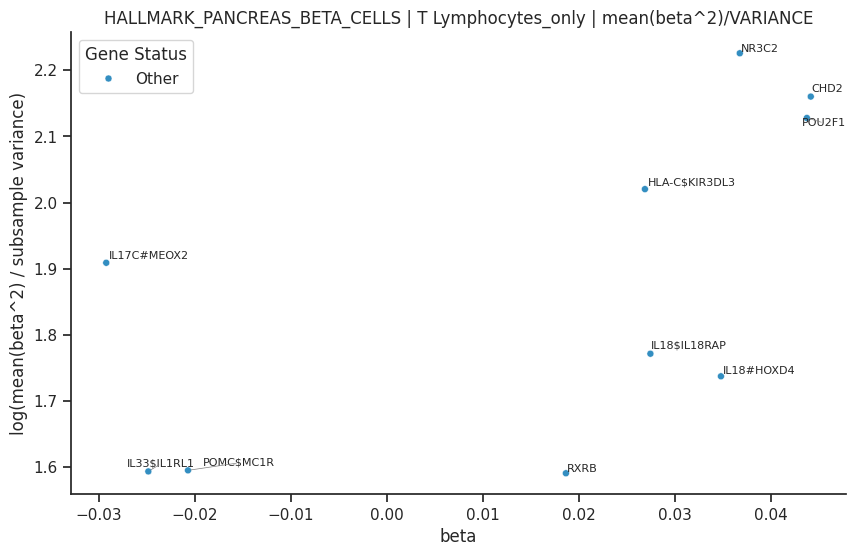

In [22]:
view('HALLMARK_PANCREAS_BETA_CELLS')

### HALLMARK_SPERMATOGENESIS

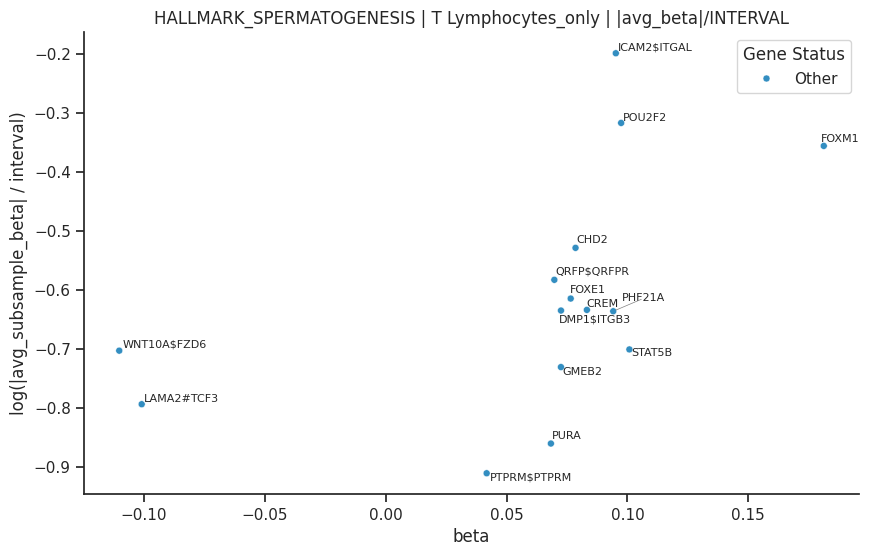

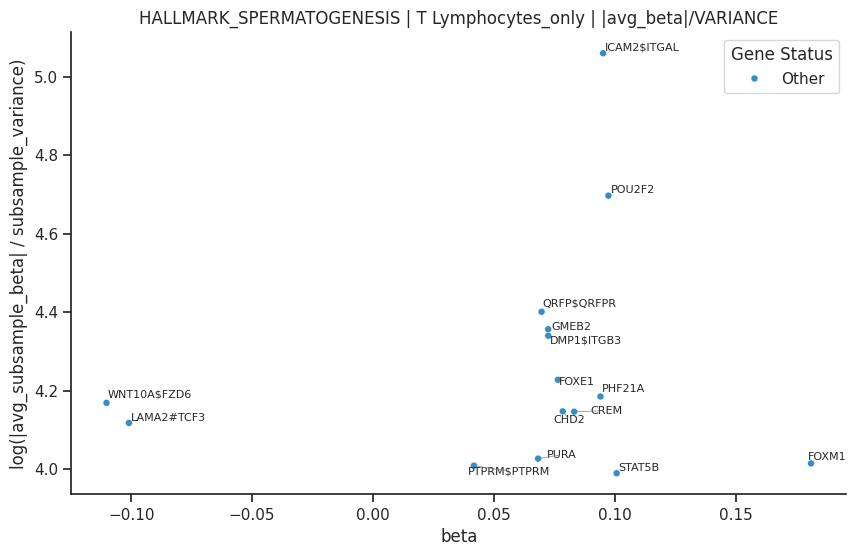

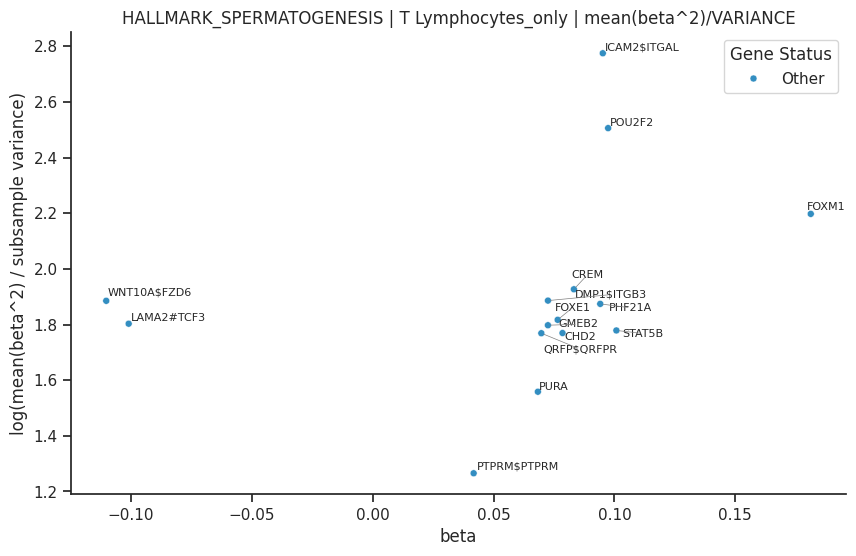

In [23]:
view('HALLMARK_SPERMATOGENESIS')

## MANUAL_ISLET_NEG_CONTROL (manual negative control)

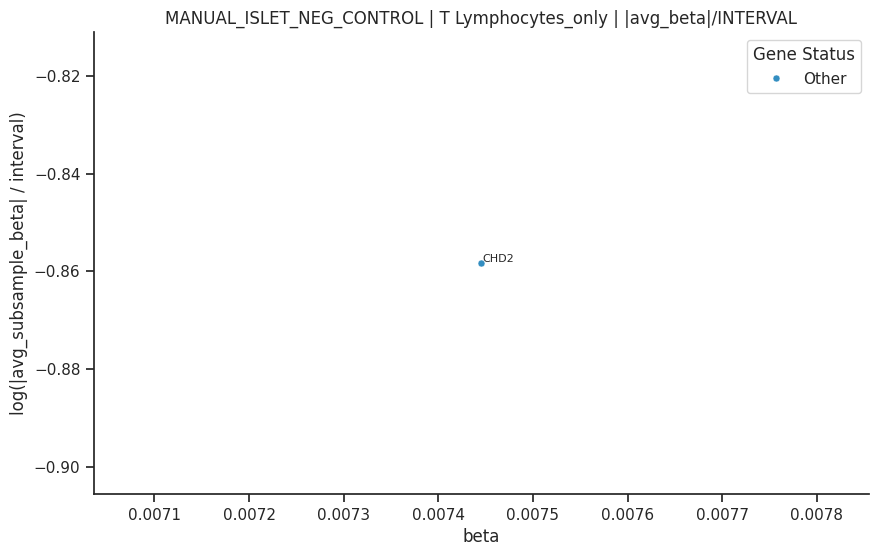

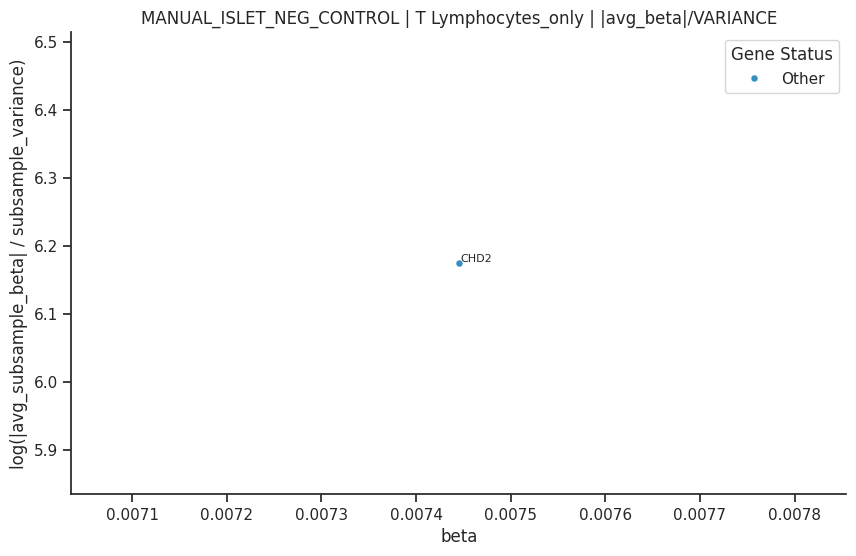

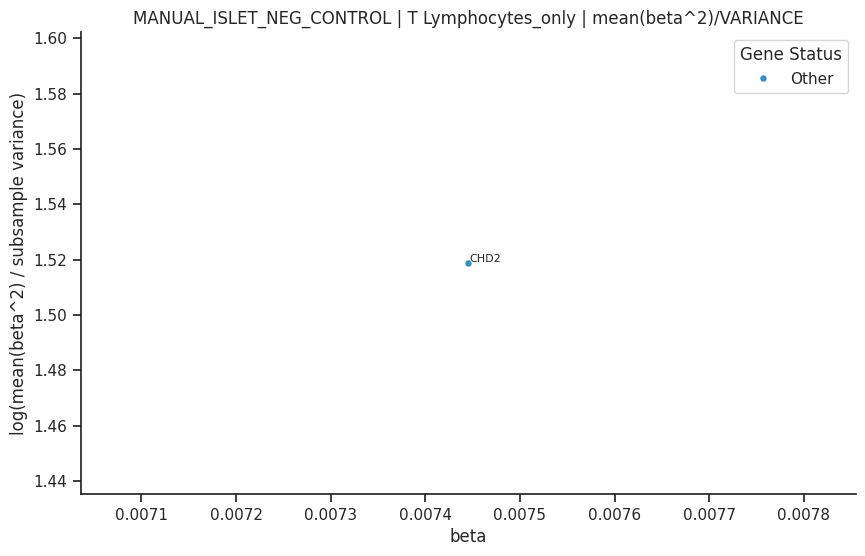

In [24]:
view('MANUAL_ISLET_NEG_CONTROL')

## Spatial gene-set panels

Spatially plot the T cells coloured by their gene-set score (others greyed), then one panel
per **significant `{cell_type}-{gene_set}` neighborhood factor**: the cells of that type
coloured by that gene set's per-cell score (others grey, T cells overlaid in red).

The per-cell-type gene-set scores are **not** cached (only the diffused `{ct}-{SET}` factors
feed the regression), so we recompute them here directly from `normalized_count` -- a plain
sum of the gene set's present genes per cell. (For the diffused factor itself instead, run
`sh.add_cancer_factors(adata, cancer_sets, annot_col=cfg.cell_type_col)` and colour by the
`obsm['x_custom']` column.)

In [25]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from metab_processing.LinearRegression.build_x import LAYER, ensure_lognorm_layer

adata = sc.read_h5ad(cfg.adata_path)
ensure_lognorm_layer(adata)
var = set(adata.var_names)
CELL_TYPE_COL = cfg.cell_type_col
TCELL_TYPES = list(cfg.t_cell_types)
# Neighborhood factors {ct}-{SET} come from ALL cell types, not just the T cells.
ALL_CELL_TYPES = None  # set after adata loads (see below)

# Gene sets behind the {ct}-{SET} neighborhood factors (present genes), incl. the vessel marker.
library = sh.load_msigdb(cfg.dbver, cfg.categories)
cancer_sets = {n: [g for g in library.get(n, []) if g in var] for n in cfg.cancer_factors}
cancer_sets.update({v: [g for g in gl if g in var] for v, gl in cfg.vessel.items()})
cancer_sets = {k: v for k, v in cancer_sets.items() if v}
ALL_CELL_TYPES = sorted(adata.obs[CELL_TYPE_COL].astype(str).unique())
print(adata.n_obs, 'cells |', len(cancer_sets), 'cancer gene sets |',
      'cell types:', sorted(adata.obs[CELL_TYPE_COL].astype(str).unique())[:12])

170045 cells | 21 cancer gene sets | cell types: ['11q13 High Grade DCIS Cells', '11q13 High Grade DCIS Cells (Mitotic)', '11q13 High Grade DCIS Tumor Cells (G1/S)', 'Apocrine Cells', 'Basal-like Structured DCIS Cells', 'CAFs, High Grade DCIS Associated', 'CAFs, Low Grade DCIS Associated', 'CXCL14+ Fibroblasts', 'Dendritic Cells', 'Endothelial Cells', 'Luminal-like Amorphous DCIS Cells', 'Macrophages']


In [47]:
def gene_set_score(adata, genes):
    """Per-cell sum of a gene set's `normalized_count` expression (present genes only). This
    is the SAME quantity the model uses: `normalized_count` is log1p(raw), so this is the sum
    of the logged expressions -- identical to the signature pseudo-gene score and to the
    neighborhood-factor `setexpr` (sum over the set before diffusion)."""
    present = [g for g in genes if g in adata.var_names]
    if not present:
        return np.zeros(adata.n_obs)
    return adata[:, present].to_df(LAYER)[present].sum(axis=1).to_numpy()


def significant_neighborhood_factors(res, cell_types, sets_dict, touch_zero=True):
    """From a target's `res`, the significant neighborhood factors (subsample interval excludes
    0), ordered by |beta| descending. Returns (cell_type, name, genes): a `{ct}-{SET}` factor
    gives (ct, SET, set_genes); a significant `{ct}-proximity` factor gives (ct, 'proximity',
    None) -- shown as a presence panel (where that cell type is), since there is no gene set."""
    if res is None or res.empty:
        return []
    sig = sh.filter_nonzero_interval(res, touch_zero=touch_zero).copy()
    sig = sig.reindex(sig['beta'].abs().sort_values(ascending=False).index)
    out = []
    for f in sig['factor']:
        for ct in cell_types:
            if f == f'{ct}-proximity':
                out.append((ct, 'proximity', None)); break
            hit = next((name for name in sets_dict if f == f'{ct}-{name}'), None)
            if hit is not None:
                out.append((ct, hit, sets_dict[hit])); break
    return out


def plot_spatial_gene_set_panels(adata, cell_type_col, tcell_types, tcell_genes, panels,
                                 point_size=3, overlay_tcells=True, cmap='viridis',
                                 tcell_label='T cells'):
    """Row of spatial panels: panel 0 = T cells coloured by `tcell_genes` score (others grey);
    then one panel per (cell_type, name, genes) in `panels`. For a gene-set factor the cells of
    that type are coloured by the set's per-cell score; for a proximity factor (genes is None)
    they're just highlighted (presence). Others grey, T cells underlaid in red. Returns the fig."""
    xy = np.asarray(adata.obsm['spatial'])
    ct = adata.obs[cell_type_col].astype(str).to_numpy()
    tmask = np.isin(ct, [str(t) for t in tcell_types])

    def _grey(ax, mask):
        ax.scatter(xy[~mask, 0], xy[~mask, 1], s=point_size * 0.5, c='lightgrey', linewidths=0)

    def _finish(ax, title):
        ax.set_title(title, fontsize=9); ax.set_aspect('equal')
        ax.set_xticks([]); ax.set_yticks([])

    def _score_panel(ax, mask, values, title):
        _grey(ax, mask)
        if overlay_tcells:
            ax.scatter(xy[tmask, 0], xy[tmask, 1], s=point_size, c='salmon', alpha=0.5, linewidths=0)
        vmax = float(np.nanpercentile(values[mask], 95)) if mask.sum() else None  # cap display at p95
        sc_ = ax.scatter(xy[mask, 0], xy[mask, 1], s=point_size, c=values[mask], cmap=cmap,
                         vmax=vmax, linewidths=0)
        plt.colorbar(sc_, ax=ax, shrink=0.7); _finish(ax, title)

    def _presence_panel(ax, mask, title):   # proximity: no gene set -> just show the cells
        _grey(ax, mask)
        if overlay_tcells:
            ax.scatter(xy[tmask, 0], xy[tmask, 1], s=point_size, c='red', linewidths=0)
        ax.scatter(xy[mask, 0], xy[mask, 1], s=point_size, c='#D55E00', linewidths=0)
        _finish(ax, title)

    n = 1 + len(panels)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5), squeeze=False)
    axes = axes[0]
    _score_panel(axes[0], tmask, gene_set_score(adata, tcell_genes), f'{tcell_label}: target gene-set score')
    for ax, (pct, name, genes) in zip(axes[1:], panels):
        if genes is None:
            _presence_panel(ax, ct == pct, f'{pct}\n{name}')
        else:
            _score_panel(ax, ct == pct, gene_set_score(adata, genes), f'{pct}\n{name}')
    fig.tight_layout()
    return fig

In [61]:
from matplotlib.lines import Line2D
import numpy as np
import matplotlib.pyplot as plt

def plot_spatial_threshold_panels(adata, cell_type_col, tcell_types, tcell_genes, panels,
                                  tcell_pct=50, other_pct=50, point_size=3,
                                  tcell_label='T cells'):
    """
    Row of spatial panels plotting cells binarized by gene-set score percentiles.
    Panel 0 = T cells coloured by whether their `tcell_genes` score is above/below `tcell_pct`.
    Subsequent panels plot T cells (underlaid) and the target cell type (overlaid), 
    coloured by whether they fall above/below their respective percentile thresholds.
    """
    xy = np.asarray(adata.obsm['spatial'])
    ct = adata.obs[cell_type_col].astype(str).to_numpy()
    tmask = np.isin(ct, [str(t) for t in tcell_types])

    # Colors
    c_t_above = 'salmon'
    c_t_below = 'lightsteelblue'
    c_o_above = 'forestgreen'
    c_o_below = 'palegreen'
    c_prox = 'forestgreen'

    # Calculate T cell scores and threshold globally for the plot
    tcell_scores = gene_set_score(adata, tcell_genes)
    t_thresh = np.nanpercentile(tcell_scores[tmask], tcell_pct) if tmask.sum() > 0 else 0
    
    t_below_mask = tmask & (tcell_scores <= t_thresh)
    t_above_mask = tmask & (tcell_scores > t_thresh)

    def _grey_bg(ax, bg_mask):
        ax.scatter(xy[bg_mask, 0], xy[bg_mask, 1], s=point_size * 0.5, c='lightgrey', linewidths=0)

    def _plot_tcells(ax):
        ax.scatter(xy[t_below_mask, 0], xy[t_below_mask, 1], s=point_size, c=c_t_below, linewidths=0)
        ax.scatter(xy[t_above_mask, 0], xy[t_above_mask, 1], s=point_size, c=c_t_above, linewidths=0)

    def _finish_and_legend(ax, title, legend_elements):
        ax.set_title(title, fontsize=9)
        ax.set_aspect('equal')
        ax.set_xticks([]); ax.set_yticks([])
        # Place legend completely outside the plot, centered below the axis
        ax.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, -0.05), 
                  fontsize=7, framealpha=0.8, handletextpad=0.1)

    def _mk_proxy(color, label):
        return Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=5, label=label)

    n = 1 + len(panels)
    # Increased height from 5 to 6 to make room for the legends below the plots
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 6), squeeze=False)
    axes = axes[0]

    # --- Panel 0: T cells only ---
    ax = axes[0]
    _grey_bg(ax, ~tmask)
    _plot_tcells(ax)
    
    leg_t = [
        _mk_proxy(c_t_above, f'{tcell_label} > {tcell_pct}%'),
        _mk_proxy(c_t_below, f'{tcell_label} $\leq$ {tcell_pct}%')
    ]
    _finish_and_legend(ax, f'{tcell_label}: Target Set', leg_t)

    # --- Subsequent Panels ---
    for ax, (pct_ct, name, genes) in zip(axes[1:], panels):
        other_mask = (ct == pct_ct)
        bg_mask = ~(tmask | other_mask)
        
        # Plot background and underlaid T cells
        _grey_bg(ax, bg_mask)
        _plot_tcells(ax)
        
        leg = list(leg_t) # Copy T cell legend items
        
        if genes is None:
            # Proximity factor: no gene set to threshold, just show presence
            ax.scatter(xy[other_mask, 0], xy[other_mask, 1], s=point_size, c=c_prox, linewidths=0)
            leg.append(_mk_proxy(c_prox, f'{pct_ct} (Presence)'))
        else:
            # Gene set factor: threshold the current cell type
            o_scores = gene_set_score(adata, genes)
            o_thresh = np.nanpercentile(o_scores[other_mask], other_pct) if other_mask.sum() > 0 else 0
            
            o_below_mask = other_mask & (o_scores <= o_thresh)
            o_above_mask = other_mask & (o_scores > o_thresh)
            
            ax.scatter(xy[o_below_mask, 0], xy[o_below_mask, 1], s=point_size, c=c_o_below, linewidths=0)
            ax.scatter(xy[o_above_mask, 0], xy[o_above_mask, 1], s=point_size, c=c_o_above, linewidths=0)
            
            leg.extend([
                _mk_proxy(c_o_above, f'{pct_ct} > {other_pct}%'),
                _mk_proxy(c_o_below, f'{pct_ct} $\leq$ {other_pct}%')
            ])
            
        _finish_and_legend(ax, f'{pct_ct}\n{name}', leg)
        
    fig.tight_layout()
    return fig

<>:62: SyntaxWarning: invalid escape sequence '\l'
<>:94: SyntaxWarning: invalid escape sequence '\l'
<>:62: SyntaxWarning: invalid escape sequence '\l'
<>:94: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_323597/1574981727.py:62: SyntaxWarning: invalid escape sequence '\l'
  _mk_proxy(c_t_below, f'{tcell_label} $\leq$ {tcell_pct}%')
/tmp/ipykernel_323597/1574981727.py:94: SyntaxWarning: invalid escape sequence '\l'
  _mk_proxy(c_o_below, f'{pct_ct} $\leq$ {other_pct}%')


## Example -- pick a target signature, show its significant neighborhood sources

HALLMARK_INTERFERON_GAMMA_RESPONSE | T Lymphocytes_only: 1 significant {ct}-{set} neighborhood factors


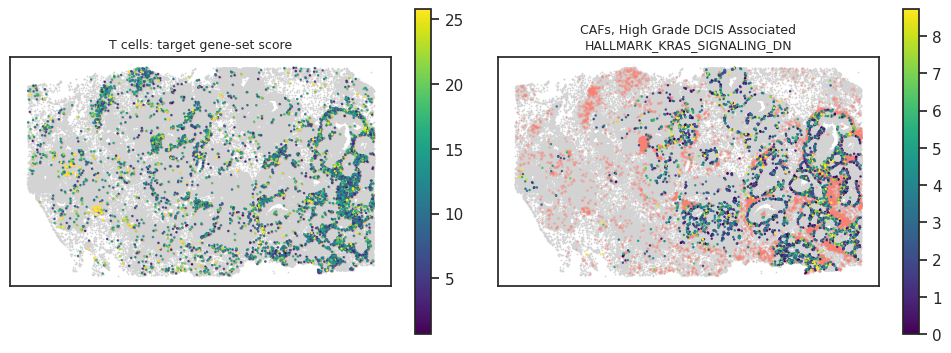

In [48]:
SIG = 'HALLMARK_INTERFERON_GAMMA_RESPONSE'      # <- any target in TARGETS
LABEL = sb.runspecs(cfg)[0]['label']            # breast has one T type -> 'T Lymphocytes_only'

res = sb.load_res(cfg, SIG, LABEL, **READ)
panels = significant_neighborhood_factors(res, ALL_CELL_TYPES, cancer_sets)
print(f'{SIG} | {LABEL}: {len(panels)} significant {{ct}}-{{set}} neighborhood factors')

# genes actually scored for the signature (after factor removal), else its present genes
m = membership.get(SIG, {})
tcell_genes = m.get('remaining') or m.get('present', [])

if res is not None:
    plot_spatial_gene_set_panels(adata, CELL_TYPE_COL, TCELL_TYPES, tcell_genes,
                                 panels[:8]);     # cap panels for a readable row

## Spatial panels for every target

KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY: 1 significant {ct}-{set} neighborhood factors
KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY: 3 significant {ct}-{set} neighborhood factors
HALLMARK_TNFA_SIGNALING_VIA_NFKB: 1 significant {ct}-{set} neighborhood factors
HALLMARK_INTERFERON_GAMMA_RESPONSE: 1 significant {ct}-{set} neighborhood factors
HALLMARK_INTERFERON_ALPHA_RESPONSE: 2 significant {ct}-{set} neighborhood factors
not yet computed: HALLMARK_HYPOXIA
not yet computed: HALLMARK_GLYCOLYSIS
not yet computed: HALLMARK_OXIDATIVE_PHOSPHORYLATION
not yet computed: HALLMARK_FATTY_ACID_METABOLISM
not yet computed: HALLMARK_MTORC1_SIGNALING


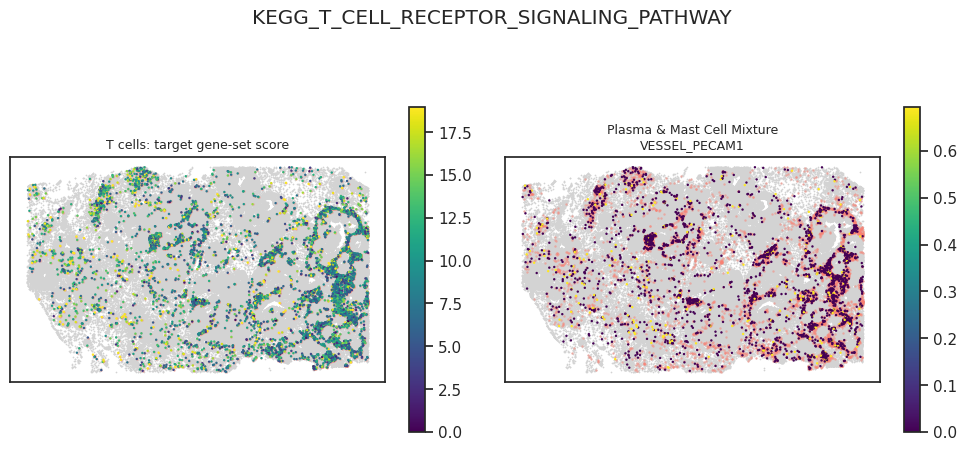

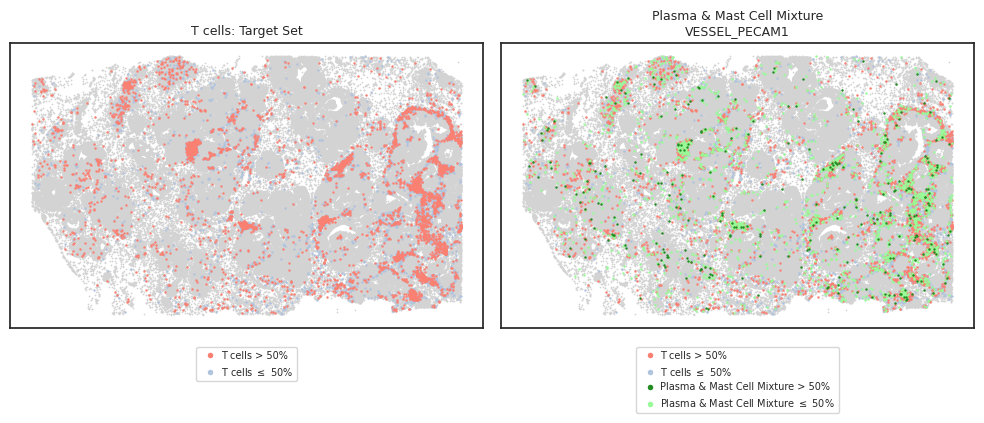

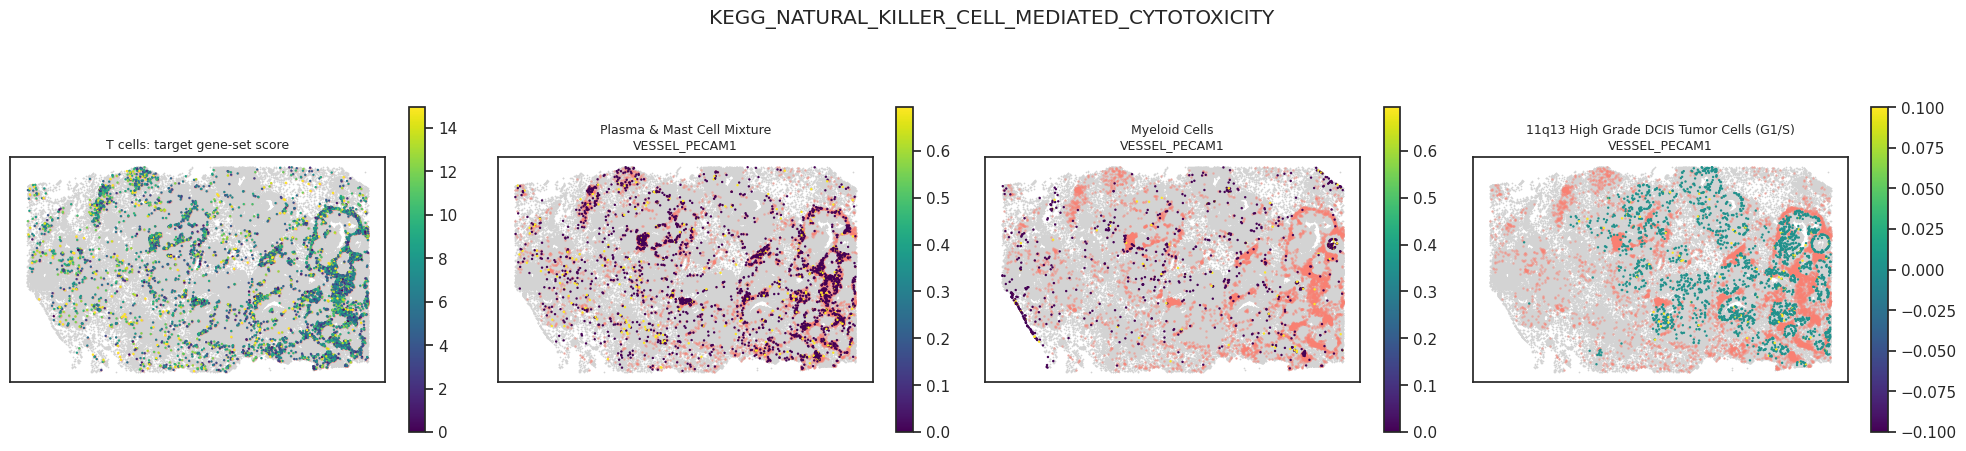

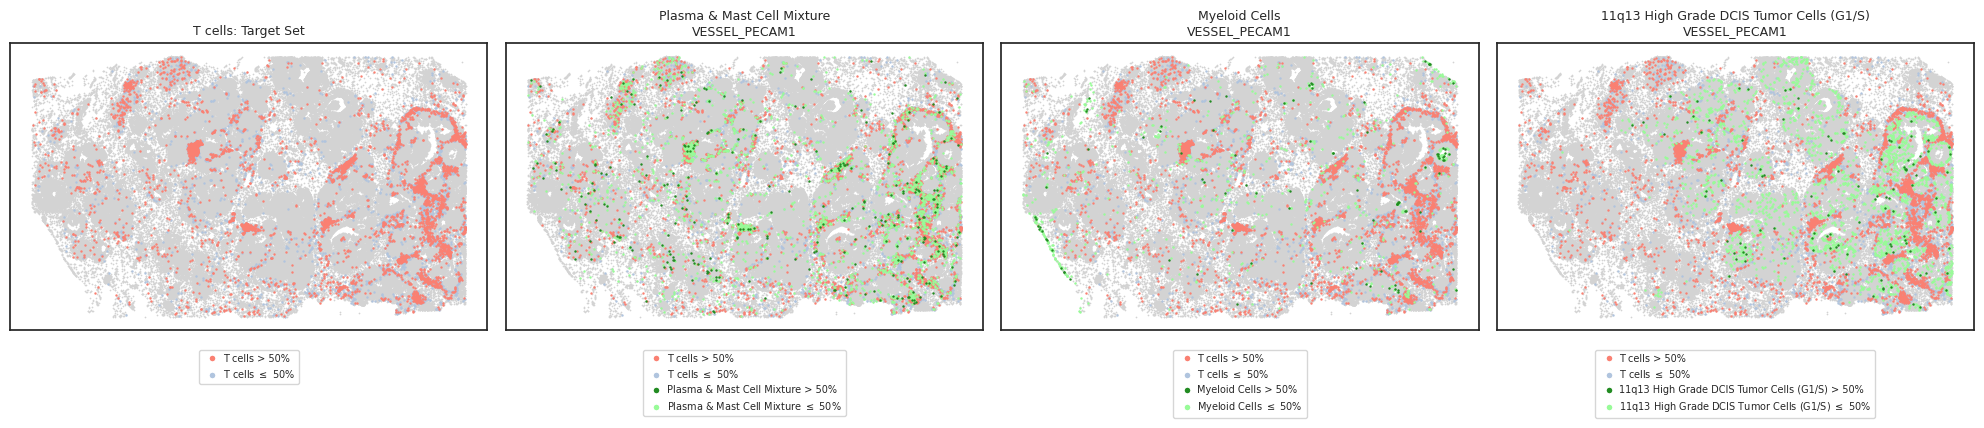

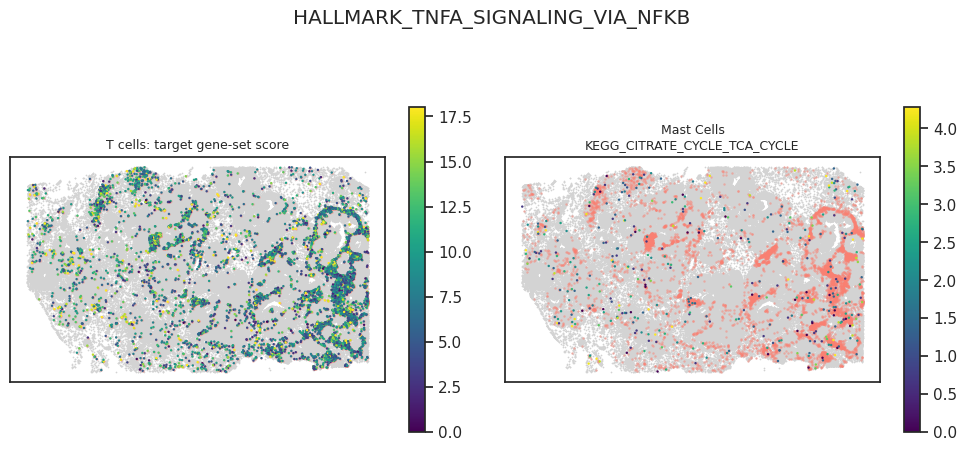

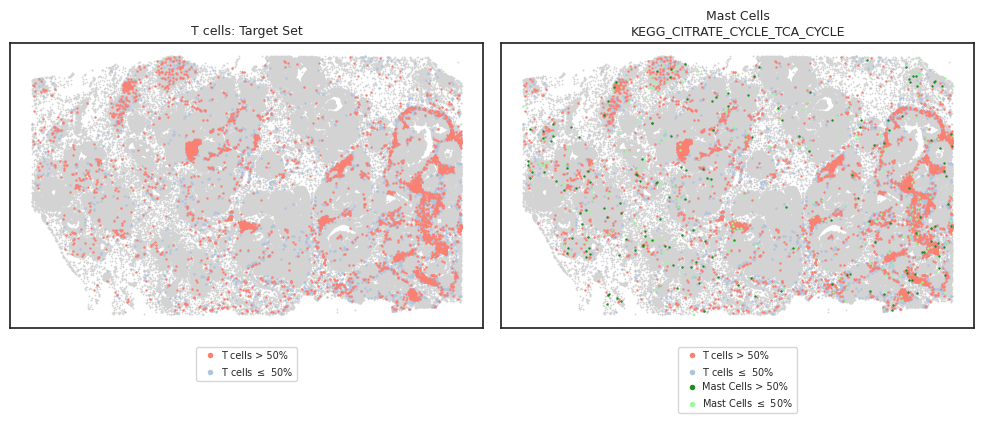

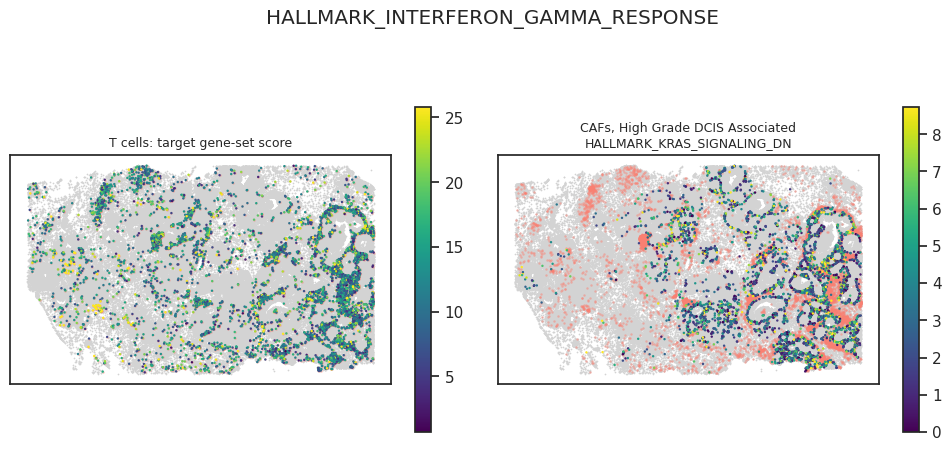

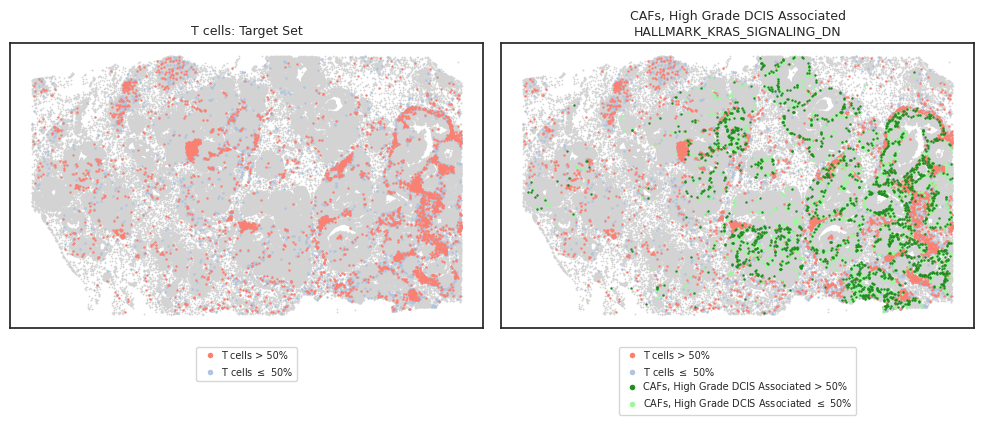

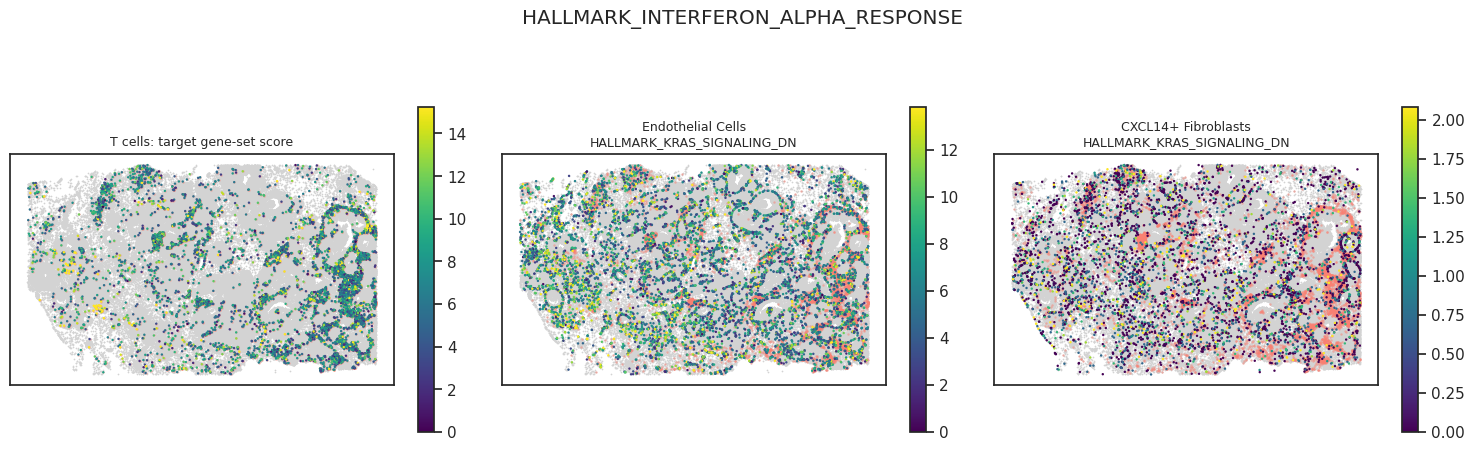

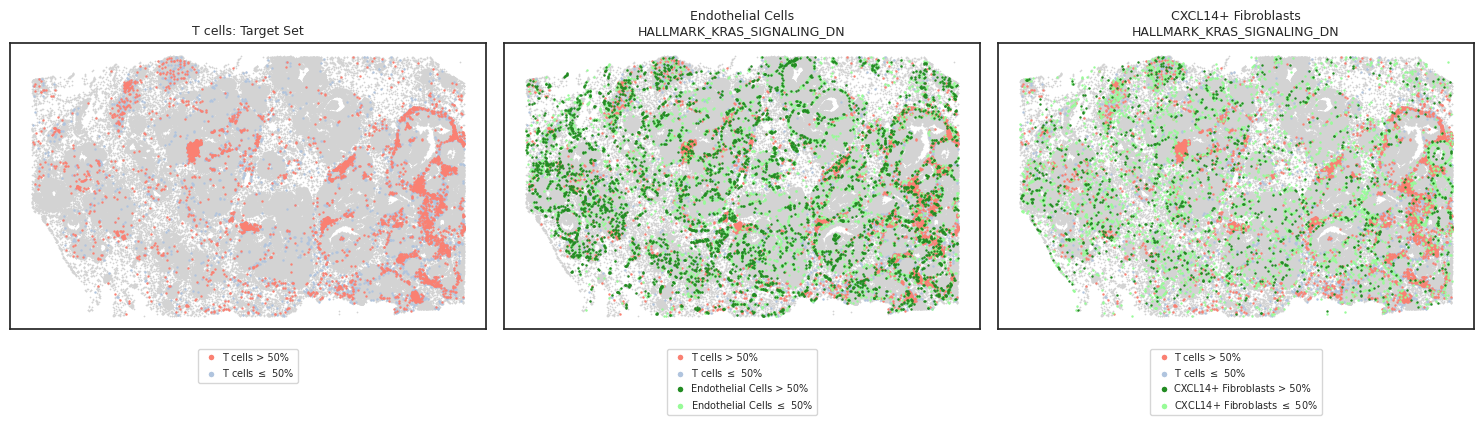

In [63]:
def spatial_view(sig, top=8):
    label = sb.runspecs(cfg)[0]['label']           # breast: single T type -> '<ct>_only'
    res = sb.load_res(cfg, sig, label, **READ)
    if res is None:
        print('not yet computed:', sig); return
    panels = significant_neighborhood_factors(res, ALL_CELL_TYPES, cancer_sets)
    if len(panels) == 0:
        return
    m = membership.get(sig, {})
    tcell_genes = m.get('remaining') or m.get('present', [])
    print(f'{sig}: {len(panels)} significant {{ct}}-{{set}} neighborhood factors')
    fig = plot_spatial_gene_set_panels(adata, CELL_TYPE_COL, TCELL_TYPES, tcell_genes, panels[:top])
    plot_spatial_threshold_panels(adata, CELL_TYPE_COL, TCELL_TYPES, tcell_genes, panels[:top])
    fig.suptitle(sig, y=1.02)


for sig in TARGETS:
    spatial_view(sig)

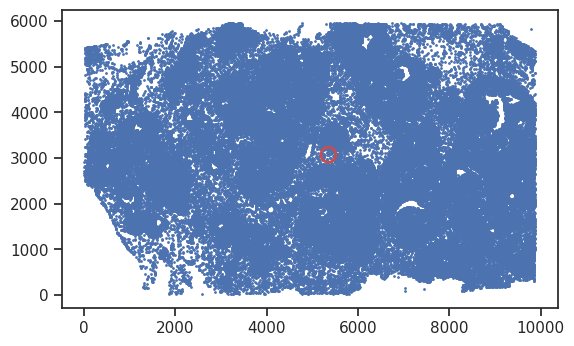

In [50]:
from sklearn.neighbors import NearestNeighbors; import numpy as np, matplotlib.pyplot as plt; xy=adata.obsm['spatial']; r=300*np.median(NearestNeighbors(n_neighbors=2).fit(xy).kneighbors(xy)[0][:,1])/15; plt.scatter(xy[:,0],xy[:,1],s=1); plt.gca().add_patch(plt.Circle(xy.mean(0),r,color='r',fill=False,lw=2)); plt.gca().set_aspect('equal'); plt.show()